# Reciprocal-space grids and scattering data

This notebook shows how to describe reciprocal-space grids, load and label scattering data, write DISCUS
Fourier macros with Bragg subtraction and LOTS, subtract or mask Bragg peaks, compute a 3D-ΔPDF, and
export to xarray, HDF5, VTK/ParaView and Mantid. It uses **real data already in the repository**: the
DISCUS 6.23.01 C3/C4 fixtures, the recorded DISCUS runs in `benchmarks/discus_6_23_01/b_probes/` and the
Mantid 7.0.0 fixtures (`tests/fixtures/mantid_7_0_0/`). DISCUS and Mantid are not needed; the macros shown
are the ones whose output is in those recorded runs.

| Notebook section | Topic | Reference doc |
|---|---|---|
| 1 | `ReciprocalGrid` | [RECIPROCAL_GRID.md](../docs/RECIPROCAL_GRID.md) |
| 2, 5–7 | `ScatteringVolume`, masks, xarray, HDF5 | [SCATTERING_DATA.md](../docs/SCATTERING_DATA.md) |
| 3–4 | `FourierConfig`: `set aver` and LOTS | [FOURIER_CONTROLS.md](../docs/FOURIER_CONTROLS.md) |
| 2, 4, 8 | slices, isosurfaces, VTK | [VISUALIZATION.md](../docs/VISUALIZATION.md) |
| 9 | Mantid MDHisto import/export | [MANTID_IO.md](../docs/MANTID_IO.md) |

Optional extras: `data` (h5py, xarray) is needed; `viz` (scikit-image) only for the isosurface cell.

In [1]:
from pathlib import Path
import os, sys, json, tempfile
sys.path.insert(0, str(Path.cwd().parent))
os.chdir(Path.cwd().parent)                     # repository root, like the other notebooks

import numpy as np
import matplotlib.pyplot as plt
from discuspdf import (Lattice, ReciprocalGrid, ScatteringVolume, read_discus_volume, mask_near_bragg,
                       FourierConfig, Lots, Seed, StructureSource,
                       SampledVolume, plot_slice, write_vtk, read_vtk,
                       read_mantid_mdhisto, write_mantid_mdhisto)

FIX = Path("tests/fixtures/discus_6.23.01")
EV = Path("benchmarks/discus_6_23_01/b_probes/evidence/20261031T182936Z_LAPTOP-NGU3BT0N")
MANTID = Path("tests/fixtures/mantid_7_0_0")
OUT = Path(tempfile.mkdtemp(prefix="discuspdf_nb07_"))   # everything written here is temporary
np.set_printoptions(precision=4, suppress=True)

## 1. Reciprocal-space grids

A `ReciprocalGrid` says where the samples are: point `i` sits at `hkl = corner + i @ axis_vectors` on a
`Lattice`, and Cartesian Q = 2π·hkl·B. The DISCUS C4 fixture was calculated on a deliberately **skewed**
grid in a monoclinic cell (a, b, c = 5, 6, 7 Å, β = 105°); its macro gave the corners below.

In [2]:
lat = Lattice.from_parameters(5, 6, 7, 90, 105, 90)
c4_macro = ReciprocalGrid.from_corners(lat, ll=(-4, -5, -6), lr=(4, -5, -6), ul=(-3, 5, -6), tl=(-4, -5, 6),
                                       shape=(33, 41, 49))
c4_file = ReciprocalGrid.from_discus_volume(read_discus_volume(FIX / "C4_total.h5"))
print("grid from the macro == grid in the engine's file:", c4_macro.isclose(c4_file, rtol=0, atol=1e-6))
print("axis_vectors (row k = hkl step of axis k):\n", c4_file.axis_vectors)
print(c4_file.fft_compatibility())

# Q of the (1, 0, 1) reflection and the textbook monoclinic d-spacing
centred = ReciprocalGrid.centered(lat, (9, 9, 9), (1, 1, 1))
i = tuple(int(x) for x in np.round(centred.hkl_to_index((1, 0, 1))))
sb, cb = np.sin(np.radians(105)), np.cos(np.radians(105))
d_ref = 1 / np.sqrt((1/25 + 1/49 - 2*cb/35) / sb**2)
print(f"|Q(1 0 1)| = {centred.q_magnitude()[i]:.6f} 1/Å, 2π/d = {2*np.pi/d_ref:.6f} 1/Å")

grid from the macro == grid in the engine's file: True
axis_vectors (row k = hkl step of axis k):
 [[0.25  0.    0.   ]
 [0.025 0.25  0.   ]
 [0.    0.    0.25 ]]
FFTCompatibility(fractional=False, cartesian=False, reasons=('hkl = 0 is not at index n//2 on every axis (centred FFT would be mis-phased)', 'fractional: grid is skewed in hkl (non-diagonal axis_vectors)', 'cartesian: Q steps are not parallel to +x, +y, +z for this lattice orientation (use the fractional transform for non-orthogonal cells)'))
|Q(1 0 1)| = 1.783769 1/Å, 2π/d = 1.783769 1/Å


## 2. DISCUS output as labelled data, and its transform

`ScatteringVolume.from_discus_file` reads any DISCUS 6.23.01 `form nexus` hkl file (volumes, planes,
lines) with its grid, Bragg label and provenance. C3 is total scattering (Bragg present), so its
transform is a **Patterson** function, not a ΔPDF. `SampledVolume` puts both on physical axes
(Å⁻¹ and Å) and `plot_slice` draws layers with their true geometry; the monoclinic angle is visible.

bragg_present (33, 41, 49) sha256 0885afcac6ad …


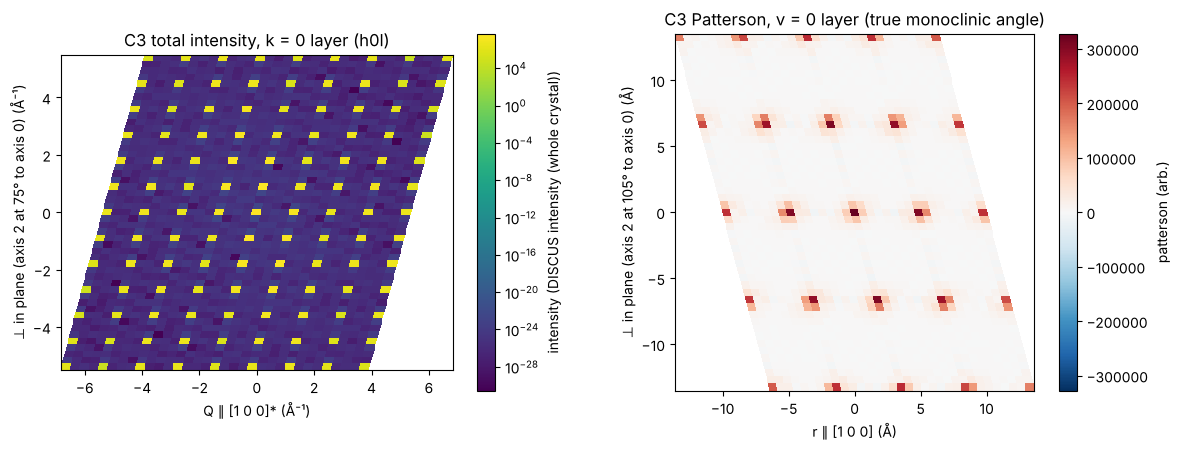

In [3]:
c3 = ScatteringVolume.from_discus_file(FIX / "C3_total.h5")
print(c3.bragg, c3.grid.shape, "sha256", c3.provenance["sha256"][:12], "…")
patterson = c3.delta_pdf(require_diffuse=False)      # refuses without require_diffuse=False

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_slice(SampledVolume.from_scattering_volume(c3), axis=1, log=True, ax=axes[0],
           title="C3 total intensity, k = 0 layer (h0l)")
plot_slice(SampledVolume.from_fractional_fft(patterson, quantity="patterson"), axis=1, ax=axes[1],
           title="C3 Patterson, v = 0 layer (true monoclinic angle)")
plt.tight_layout()

## 3. Writing a DISCUS Fourier macro: `set aver` and LOTS

`FourierConfig` writes the `fourier`/`output` blocks with only commands whose behaviour was observed on
DISCUS 6.23.01 (`b_probes/RESULT.md`). The config below is the one behind probe `p4_turbo_g32_a100`:
the correlated Cu/Au "block" model (16³ cells, a = 4 Å), `set aver,100`, on a grid commensurate with
the crystal.

In [4]:
cubic = Lattice.from_parameters(4, 4, 4, 90, 90, 90)
g32 = ReciprocalGrid.from_ranges(cubic, *[(-2.0, 1.875, 32)] * 3)
cfg = FourierConfig(g32, outputs=(("int", "p4_turbo_g32_a100_int.h5"),), aver_percent=100)
block = StructureSource.stru("gate2_block.stru", crystal_cells=(16, 16, 16))
print(cfg.render(block))
print("Bragg label of the output:", cfg.bragg)

discus
read
  stru gate2_block.stru
eval n[1]
eval n[2]
eval n[3]
fourier
  xray
  wvle moa1
  ll -2,-2,-2
  lr 1.875,-2,-2
  ul -2,1.875,-2
  tl -2,-2,1.875
  na 32
  no 32
  nt 32
  abs h
  ord k
  top l
  temp ignore
  disp off
  lots off
  set technique:turbo
  set aver,100.0
  show
  run
exit
output
  value int
  form nexus
  outf p4_turbo_g32_a100_int.h5
  run
exit
exit
exit

Bragg label of the output: bragg_subtracted


The refusals are part of the API: each one is a 6.23.01 behaviour the probes found.

In [5]:
attempts = {
    "set aver 50 without a seed": lambda: FourierConfig(g32, (("int", "x.h5"),), aver_percent=50),
    "1-value seed": lambda: Seed((1234,)),
    "LOTS with value real": lambda: FourierConfig(g32, (("real", "x.h5"),), lots=Lots("box", (4, 4, 4), "all", True)),
    "lot larger than crystal": lambda: FourierConfig(g32, (("int", "x.h5"),),
                                                     lots=Lots("box", (17, 17, 17), "all", True)).render(block),
}
for what, attempt in attempts.items():
    try:
        attempt()
        print(f"{what}: accepted")
    except ValueError as exc:
        print(f"{what}: refused — {exc}")
print("nufft option exists:", "technique" in FourierConfig.__dataclass_fields__)

lots_cfg = FourierConfig(g32, (("int", "lots.h5"),), seed=Seed((11, 22, 33, 44, 55, 66, 77, 88)),
                         lots=Lots("box", (4, 4, 4), 64, periodic=True))
print([line for line in lots_cfg.render(block).splitlines() if line.startswith(("seed", "  lots"))])

set aver 50 without a seed: refused — set aver,50 draws unit cells at random; give an explicit 8-value Seed
1-value seed: refused — Seed needs exactly 8 values; DISCUS 6.23.01 fills missing words from the clock
LOTS with value real: refused — with lots DISCUS writes only 'int' (6.23.01 refused 'real', error -60)
lot larger than crystal: refused — lot size (17, 17, 17) exceeds the crystal (16, 16, 16) (DISCUS error -101)
nufft option exists: False
['seed 11,22,33,44,55,66,77,88', '  lots box,4,4,4,64,y']


## 4. Bragg subtraction and the 3D-ΔPDF of a correlated model

Loading the probe output **with its config** checks that the file is what the config wrote (name,
`value`, Bragg label, grid) and keeps the config in the provenance. `set aver,100` subtracts the
average amplitude: on this commensurate grid the off-Bragg intensity is unchanged and the 64 Bragg
voxels become zero.

bragg_present -> bragg_subtracted | config kept: 100.0
Bragg voxels: 64 | max total there: 4.89e+10 | max after set aver 100: 0.0
off-Bragg change (relative): 4.024526274475744e-15


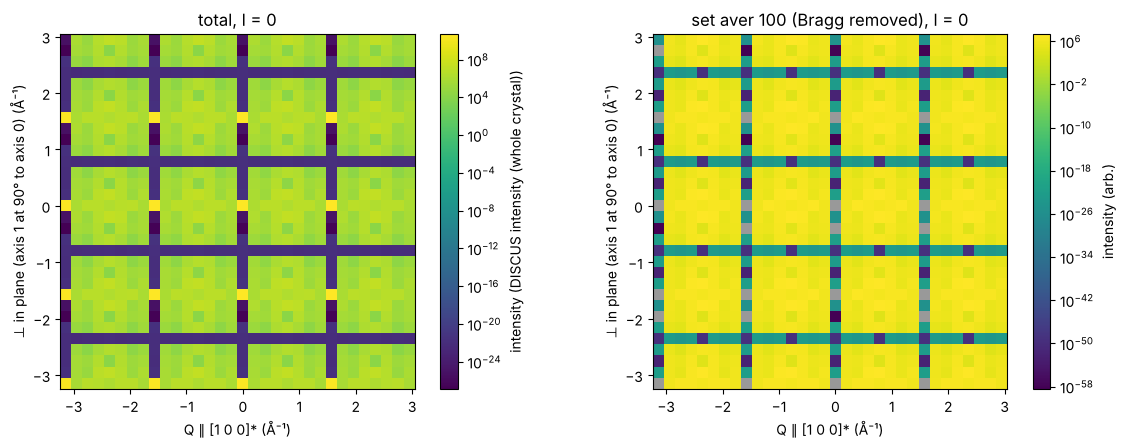

In [6]:
total = ScatteringVolume.from_discus_file(EV / "p4_turbo_g32_a0" / "p4_turbo_g32_a0_int.h5")
diffuse = ScatteringVolume.from_discus_file(EV / "p4_turbo_g32_a100" / "p4_turbo_g32_a100_int.h5", config=cfg)
print(total.bragg, "->", diffuse.bragg, "| config kept:", diffuse.provenance["fourier_config"]["aver_percent"])
bragg = mask_near_bragg(g32, 0.05)                    # exactly the 64 integer-hkl voxels here
print("Bragg voxels:", int(bragg.sum()),
      "| max total there:", f"{total.intensity[bragg].max():.3g}",
      "| max after set aver 100:", diffuse.intensity[bragg].max())
print("off-Bragg change (relative):",
      np.linalg.norm(diffuse.intensity[~bragg] - total.intensity[~bragg]) / np.linalg.norm(total.intensity[~bragg]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_slice(SampledVolume.from_scattering_volume(total), axis=2, log=True, ax=axes[0], title="total, l = 0")
d0 = SampledVolume.from_scattering_volume(diffuse)
plot_slice(SampledVolume(d0.values, d0.origin, d0.steps, "reciprocal", "intensity", signed=False,
                         index_vectors=d0.index_vectors), axis=2, log=True, ax=axes[1],
           title="set aver 100 (Bragg removed), l = 0")
plt.tight_layout()

`delta_pdf()` (the verified fractional transform, Gate 3) gives the ΔPDF in absolute units. The block
model was built with signed, **anisotropic** nearest-neighbour correlations; they show up as peaks of
opposite sign along a and b.

imaginary/real = 8.3e-16
  +a  r =  4.0 Å   ΔPDF = -7.865e+05
  +b  r =  4.0 Å   ΔPDF =  8.931e+05
  +c  r =  4.0 Å   ΔPDF =  8.254e+04
 a+b  r =  5.7 Å   ΔPDF = -3.85e+05
  2a  r =  8.0 Å   ΔPDF = -1.13e+05


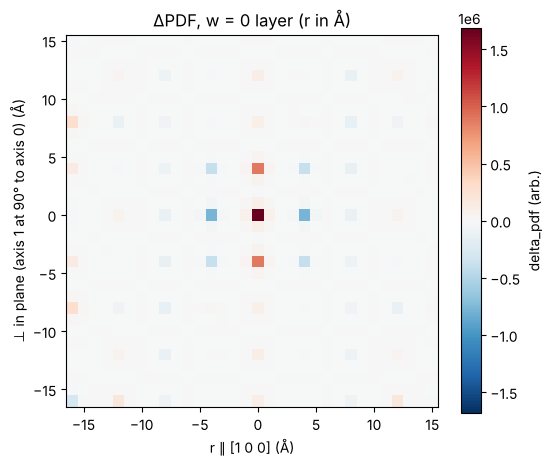

In [7]:
res = diffuse.delta_pdf()
rho = SampledVolume.from_fractional_fft(res)
print(f"imaginary/real = {res.imaginary_ratio:.1e}")
c = np.array(rho.shape) // 2
du = np.array([ax[1] - ax[0] for ax in res.u_axes])
for label, u in [("+a", (1, 0, 0)), ("+b", (0, 1, 0)), ("+c", (0, 0, 1)), ("a+b", (1, 1, 0)), ("2a", (2, 0, 0))]:
    idx = tuple(int(x) for x in np.round(c + np.array(u) / du))
    r = np.linalg.norm(np.array(u, float) @ res.direct_basis)
    print(f"{label:>4}  r = {r:4.1f} Å   ΔPDF = {rho.values[idx]: .4g}")
plot_slice(rho, axis=2, title="ΔPDF, w = 0 layer (r in Å)");

## 5. Masking instead of subtracting

For total scattering you can also **mask** the Bragg regions. Masked voxels must be filled explicitly
before a transform, and the fill is recorded. (Masking also removes the diffuse intensity inside the
mask, so the result is not identical to `set aver`.)

In [8]:
masked = total.mask_bragg(radius=0.3)                 # Å⁻¹ around every integer hkl
print(masked.bragg, masked.mask_reasons, "masked voxels:", int(masked.mask.sum()))
try:
    masked.delta_pdf()
except ValueError as exc:
    print("refused:", exc)
res_m = masked.delta_pdf(fill_masked=0.0)
print("recorded:", res_m.provenance["corrections"])
rho_m = SampledVolume.from_fractional_fft(res_m)
for label, u in [("+a", (1, 0, 0)), ("+b", (0, 1, 0))]:
    idx = tuple(int(x) for x in np.round(c + np.array(u) / du))
    print(f"{label}: masked {rho_m.values[idx]: .3g}   set aver 100 {rho.values[idx]: .3g}")

bragg_masked ('bragg: |Q - Q_hkl| <= 0.3 1/angstrom',) masked voxels: 1216
refused: 1216 voxels are masked; pass fill_masked=<value> to state what the transform should use there
recorded: ['masked voxels filled with 0']
+a: masked -7.99e+05   set aver 100 -7.86e+05
+b: masked  8.77e+05   set aver 100  8.93e+05


## 6. Planes and lines

DISCUS writes a zero step for a one-point axis, which the older `read_discus_volume` cannot read.
Probe `p1a_hk0` is an hk0 plane of GaAs.

ReciprocalGrid(plane, shape=(41, 41, 1), corner=[-2.0, -2.0, 0.0], axis_vectors=[[0.1, 0.0, 0.0], [0.0, 0.1, 0.0], [0.0, 0.0, 0.0]], Lattice(a=5.6537 Å, b=5.6537 Å, c=5.6537 Å, alpha=90°, beta=90°, gamma=90°, V=180.717 Å³))


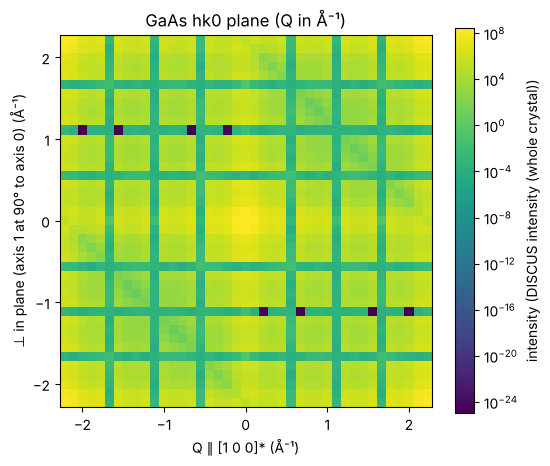

In [9]:
plane = ScatteringVolume.from_discus_file(EV / "p1a_hk0" / "p1a_hk0_int.h5")
print(plane.grid)
plot_slice(SampledVolume.from_scattering_volume(plane), axis=2, index=0, log=True, title="GaAs hk0 plane (Q in Å⁻¹)");

## 7. xarray and versioned HDF5

`to_xarray()` gives labelled data (h, k, l and qx, qy, qz coordinates where they exist); selections
come back with a correct grid. `save_hdf5` writes a versioned file with a SHA-256 per array.

In [10]:
ds = diffuse.to_xarray()
print(ds)
layer = ds.swap_dims(i0="h", i1="k", i2="l")["intensity"].sel(l=0.0)     # label-based selection
flat = layer.stack(point=("h", "k"))
h, k = flat.point.values[int(flat.argmax())]
print(f"strongest diffuse intensity in l = 0: I({h}, {k}, 0) = {float(flat.max()):.4g}")
print("same point by label:", float(layer.sel(h=h, k=k)))
sub = ScatteringVolume.from_xarray(ds.isel(i0=slice(8, 24, 2)))
print("selection's grid corner and steps:", sub.grid.corner, np.diag(sub.grid.axis_vectors))

path = diffuse.save_hdf5(OUT / "block_diffuse.h5")
back = ScatteringVolume.load_hdf5(path)
print("HDF5 round trip identical:", np.array_equal(back.intensity, diffuse.intensity), back.grid == diffuse.grid)

<xarray.Dataset> Size: 264kB
Dimensions:    (i0: 32, i1: 32, i2: 32)
Coordinates:
  * i0         (i0) int64 256B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30 31
    h          (i0) float64 256B -2.0 -1.875 -1.75 -1.625 ... 1.625 1.75 1.875
    qx         (i0) float64 256B -3.142 -2.945 -2.749 ... 2.553 2.749 2.945
  * i1         (i1) int64 256B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30 31
    k          (i1) float64 256B -2.0 -1.875 -1.75 -1.625 ... 1.625 1.75 1.875
    qy         (i1) float64 256B -3.142 -2.945 -2.749 ... 2.553 2.749 2.945
  * i2         (i2) int64 256B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30 31
    l          (i2) float64 256B -2.0 -1.875 -1.75 -1.625 ... 1.625 1.75 1.875
    qz         (i2) float64 256B -3.142 -2.945 -2.749 ... 2.553 2.749 2.945
Data variables:
    intensity  (i0, i1, i2) float64 262kB 0.0 2.241e-23 ... 9.689e+04 1.496e+06
Attributes:
    discuspdf_schema:          discuspdf.ScatteringVolume
    discuspdf_schema_version:  1
    grid:     

/usr/local/lib/python3.13/site-packages/xarray/core/dataarray.py:6563: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)


## 8. VTK for ParaView, and isosurfaces

`.vti` (ImageData) is written only when the axes run along x, y, z; anything else goes to `.vts` with
explicit point coordinates. The cubic ΔPDF qualifies for `.vti`; the monoclinic Patterson does not.

refused: ImageData (.vti) needs every axis along +x, +y, +z; this grid is oblique or non-orthogonal in Cartesian coordi …
StructuredGrid (33, 41, 49) points match: True


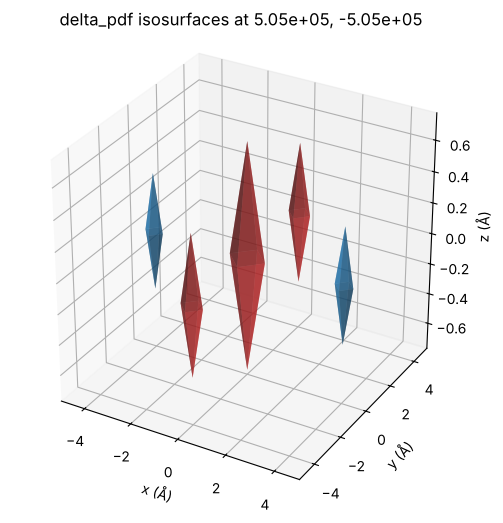

In [11]:
write_vtk(rho, OUT / "block_delta_pdf.vti")
pat = SampledVolume.from_fractional_fft(patterson, quantity="patterson")
try:
    write_vtk(pat, OUT / "c3_patterson.vti")
except ValueError as exc:
    print("refused:", str(exc)[:110], "…")
write_vtk(pat, OUT / "c3_patterson.vts")
v = read_vtk(OUT / "c3_patterson.vts")
print(v["kind"], v["shape"], "points match:", np.allclose(v["points"], pat.points()))

import importlib.util
if importlib.util.find_spec("skimage"):
    from discuspdf import plot_isosurfaces
    top = 0.3 * np.abs(rho.values).max()
    plot_isosurfaces(rho, levels=(top, -top));
else:
    print("isosurfaces need the 'viz' extra (scikit-image): pip install -e '.[viz]'")

## 9. Mantid MDHisto files

`read_mantid_mdhisto` reads Mantid `SaveMD` (v2) files in the HKL frame, applying the stored projection
and cross-checking it against the axis names and units. This fixture was written by Mantid 7.0.0 with
`BinMD` on the basis `[H,H,0]`, `[-H,H,0]`, `[0,0,L]`, with two events at known hkl.

hkl steps of the three axes:
 [[ 0.25  0.25  0.  ]
 [-0.25  0.25  0.  ]
 [ 0.    0.    0.5 ]]
['[H,H,0]: name matches transform', '[-H,H,0]: name matches transform', '[0,0,L]: name matches transform']
event at hkl (1.75, -0.5, 0.25) weight 200: grid point hkl [ 1.75 -0.5   0.25], signal 200.0
event at hkl (-2.25, -1.5, -2.25) weight 50: grid point hkl [-2.25 -1.5  -2.25], signal 50.0
written and read back: True


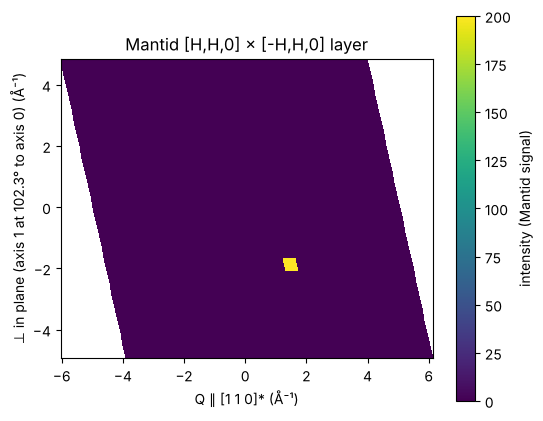

In [12]:
m = read_mantid_mdhisto(MANTID / "projected_hh0.nxs")
print("hkl steps of the three axes:\n", m.grid.axis_vectors)
print(m.provenance["consistency_checks"])
expected = json.loads((MANTID / "expected.json").read_text())["files"]["projected_hh0.nxs"]["events_hkl"]
H = m.grid.hkl()
for h, k, l, n in expected:
    i = np.unravel_index(np.argmin(np.linalg.norm(H - (h, k, l), axis=-1)), H.shape[:3])
    print(f"event at hkl ({h}, {k}, {l}) weight {n}: grid point hkl {H[i]}, signal {m.intensity[i]}")

again = read_mantid_mdhisto(write_mantid_mdhisto(m, OUT / "for_mantid.nxs"))
print("written and read back:", again.grid.isclose(m.grid, rtol=0, atol=1e-6))
plot_slice(SampledVolume.from_scattering_volume(m), axis=2, index=6, title="Mantid [H,H,0] × [-H,H,0] layer");

## What this does not show

DISCUS runs themselves (see `tests/test_fourier_live.py` and `b_probes/live_b3/results.json` for the
live evidence), and the open items listed in `todo/TASKS.md`: `set aver` with displacement disorder,
non-zero B, multi-site cells and non-commensurate grids; `value 3DPDF` with LOTS; Mantid event
workspaces and Q_lab/Q_sample frames.

In [13]:
import shutil
shutil.rmtree(OUT)                                   # remove the temporary files written above
print("removed", OUT)

removed /tmp/discuspdf_nb07_uum4h1bc
